### **Filter and Convolution**

___

**C1 (ทฤษฎี + โค้ด) Convolution คือ "เลื่อน คูณ บวก" — อ่าน ThinkDSP บทที่ 8 หัวข้อ 8.1 Smoothing และ 8.2 Convolution**
  - **ทำ:**
    - สร้าง notebook ใหม่ `notebooks/07_Filters.ipynb`
    - ทำนายก่อนรัน: convolution ของ `x = [1, 2, 3, 4]` กับ `h = [0.5, 0.5]` คิดมือ เขียนผลลง markdown
    > คิดมือแล้วผลลัพธ์ของการ convolution มีค่าเท่ากับ [0.5, 1.5, 2.5, 3.5, 2]
    - สร้างไฟล์ `dsp/filters.py` → เขียน `convolve(x, h)` พร้อม docstring ใช้ loop ซ้อน 2 ชั้นตามสูตร $y[n] = \sum_k h[k]\,x[n-k]$
    - ความยาวผลลัพธ์ = `len(x) + len(h) - 1` → ข้าม `x[n-k]` ที่ index อยู่นอกช่วง 0 ถึง `len(x) - 1`
    - ทดสอบกับตัวเลขที่ทำนายไว้ → เช็ค `np.allclose` กับ `np.convolve(x, h)`
    - ทดสอบ impulse: `convolve([0, 0, 1, 0, 0], [1, 2, 3])` → print ผล
  - **ตอบ:**
    1. `len` ของผลลัพธ์ `[1, 2, 3, 4]` กับ `[0.5, 0.5]` ได้เท่าไร
    > จากสูตรการคำนวณหาขนาดของ array ของ output array จากการทำ Convolution
    > 
    > $x_n+h_n-1$ เมื่อ $x_n$ : ขนาดของ input signal array และ $h_n$ : ขนาดของ filters
    >
    > ซึ่งมีค่าเท่ากับ $x_n+h_n-1 = 4+2-1 = 5$ 
    2. `np.allclose` กับ `np.convolve` ได้ True หรือ False
    > ผลลัพธ์อยู่ใน dsp/filters.py มีการตรวจสอบด้วย np.allclose() แล้วผลลัพธ์มีค่าเท่ากับ True
    3. ผล impulse test มีตัวเลข `[1, 2, 3]` เริ่มที่ index ไหน
    > ผล impulse test มีตัวเลขเริ่มต้นที่ index = 2 และจบที่ index = 4
  - **เสร็จเมื่อ:** import `convolve` จาก `dsp.filters` ได้ / ผลได้ `[0.5, 1.5, 2.5, 3.5, 2.0]` / `np.allclose` ได้ True / impulse test ได้ `[0, 0, 1, 2, 3, 0, 0]` และตอบครบ 3 ข้อ

In [1]:
%load_ext autoreload
%autoreload 2

import sys, os
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio

sys.path.insert(0, os.path.abspath(".."))
from dsp.filters import convolve, fft_convolve
from dsp.signal_generator import make_time, create_sin

In [2]:
x = np.array([1,2,3,4])
h = np.array([0.5, 0.5])

print(convolve(x,h))
print("Verify whether the value of np.convolve(x,h) = convolve(x,h) by using np.allclose()")
print(f"{np.allclose(convolve(x,h),np.convolve(x,h))}")

# Test with impulse 
print(f"Test convolve() with impulse : {convolve([0, 0, 1, 0, 0], [1, 2, 3])}")

[0.5 1.5 2.5 3.5 2. ]
Verify whether the value of np.convolve(x,h) = convolve(x,h) by using np.allclose()
True
Test convolve() with impulse : [0. 0. 1. 2. 3. 0. 0.]


**C2 (โค้ด + หู) Moving average เป็น low-pass filter**
  - **ทำ:**
    - `sr = 8000` สร้าง `t` 1 วินาที → `x = create_sin(1, 200, t) + create_sin(0.5, 2500, t)`
    - kernel moving average 8 จุด: `h = np.ones(8) / 8`
    - `y = np.convolve(x, h, mode='same')` → print `len(y)`
    - `X = np.abs(np.fft.rfft(x))`, `Y = np.abs(np.fft.rfft(y))`, `freqs = np.fft.rfftfreq(len(x), 1/sr)`
    - หา index ของ 200 Hz กับ 2500 Hz → print gain `Y / X` ที่สองความถี่นี้
    - ฟัง `x` กับ `y` ด้วย `Audio(..., rate=sr)`
  - **เครื่องมือใหม่:**
    - `np.convolve([1, 2, 3], [1, 1], mode='same')` → `[1, 3, 5]` (ตัดให้ยาวเท่า input ส่วนแบบ default ได้ `[1, 3, 5, 3]`)
  - **ใบ้:** C1 ผ่านแล้วใช้ `np.convolve` แทน `convolve` ของเราได้ เพราะเร็วกว่ามาก
  - **ตอบ:**
    1. gain ที่ 200 Hz ได้เท่าไร
    > gain ที่ 200 Hz มีค่าประมาณ 0.936
    2. gain ที่ 2500 Hz ได้เท่าไร
    > gain ที่ 2500 มีค่าประมาณ 0.150
    3. ฟัง `y` แล้วเสียงไหนเบาลงชัด: เสียงทุ้ม หรือเสียงแหลม
    > หลังจากฟัง y แล้วเสียงที่เบาลงชัดเจนคือ เสียงแหลมที่มีความถี่สูง เพราะ สิ่งที่กำลังทำคือการทำ low-pass filters หรือตัวกรองความถี่ต่ำผ่าน จะยอมให้ความถี่ต่ำผ่านแต่ความถี่สูงไม่ให้ผ่าน เสียงที่ได้ยินเสียงแหลมจึงเบาลงชัดเจน
  - **เสร็จเมื่อ:** `len(y)` ได้ 8000 / index ได้ 200 กับ 2500 / gain ≈0.936 กับ ≈0.150 และตอบครบ 3 ข้อ

In [3]:
sr = 8000
t = make_time(0, 1, sr)
x_signal = create_sin(1, 200, t) + create_sin(0.5, 2500, t)
h_signal = np.ones(8)/8 

y = np.convolve(x_signal, h_signal, mode="same")
print(f"The output signal array (y) size : {len(y)}")

X = np.abs(np.fft.rfft(x_signal))
Y = np.abs(np.fft.rfft(y))
freqs = np.fft.rfftfreq(len(x_signal), 1/sr)

freqs_200 = np.argmin(np.abs(freqs - 200))
freqs_2500 = np.argmin(np.abs(freqs - 2500))

X_200 = X[freqs_200]
Y_200 = Y[freqs_200]
X_2500 = X[freqs_2500]
Y_2500 = Y[freqs_2500]
print(f"Index of 200 Hz : {freqs_200} and Gain at 200 Hz : {round(Y_200/X_200,3)}")
print(f"Index of 2500 Hz : {freqs_2500} and Gain at 2500 Hz : {round(Y_2500/X_2500,3)}")

The output signal array (y) size : 8000
Index of 200 Hz : 200 and Gain at 200 Hz : 0.936
Index of 2500 Hz : 2500 and Gain at 2500 Hz : 0.15


In [4]:
# Listen x signal (the signal without low-pass filter)
Audio(x, rate=sr)

In [5]:
# Listen y signal (the signal with low-pass filters)
Audio(y, rate=sr)

**C3 (โค้ด + สังเกต) Frequency response = FFT ของ kernel — อ่าน ThinkDSP หัวข้อ 8.3 The frequency** domain
  - **ทำ:**
    - `H = np.abs(np.fft.rfft(h, n=8000))` → `freqs_h = np.fft.rfftfreq(8000, 1/sr)` → print `len(H)`
    - print `H` ที่ 200 Hz กับ 2500 Hz → เทียบกับ gain จาก C2
    - ใช้ `for M in [4, 8, 16]:` (ห้าม copy โค้ด 3 ชุด) สร้าง `h = np.ones(M) / M` แล้วคำนวณ `H`
    - ในลูป: หาความถี่แรกที่ `H` ลงไปเป็น 0 (`H < 1e-6`) → print คู่กับ `M`
    - ในลูป: พล็อต `H` เทียบ `freqs_h` ทั้ง 3 เส้นในกราฟเดียว (มี legend บอก M)
  - **เครื่องมือใหม่:**
    - `np.fft.rfft([1, 1], n=4)` → เติม 0 ท้ายให้ยาว 4 ก่อน FFT ได้ bin ละเอียดขึ้น
    - `np.argmax(np.array([5, 3, 0, 2]) < 1)` → 2 คือ index แรกที่เงื่อนไขเป็น True
  - **ตอบ:**
    1. `M = 8` มี `H` ที่ 2500 Hz เท่าไร
    > ที่ `M = 8` มี `H` ที่ 2500 Hz เท่ากับ 0.15 ซึ่งมีค่าเหมือนกับ C2 
    2. `M = 8` มี `H` เป็น 0 ครั้งแรกที่กี่ Hz
    > ที่ `M = 8` มี `H` เป็น 0 ครั้งแรกที่ความถี่เท่ากับ 1000 Hz
    3. `M` ไหนที่ปล่อยให้ความถี่ผ่านได้แคบที่สุด
    > จากการสังเกตกราฟ `M` ที่ปล่อยให้ความถี่ผ่านได้แคบที่สุด คือ M = 16
  - **เสร็จเมื่อ:** `len(H)` ได้ 4001 / M = 8: `H` ที่ 200 Hz ≈0.936 และที่ 2500 Hz ≈0.150 ตรงกับ C2 / ความถี่ที่เป็น 0 ครั้งแรก M = 4, 8, 16 ได้ 2000, 1000, 500 Hz / มีกราฟ 3 เส้นจากลูปเดียว และตอบครบ 3 ข้อ

The filter coefficients (h) size after FFT : 4001
The filter coefficients (h) at 200 Hz : 0.936
The filter coefficients (h) at 2500 Hz : 0.15
M = 4 and the first frequency the approches 0 is 2000.0
M = 8 and the first frequency the approches 0 is 1000.0
M = 16 and the first frequency the approches 0 is 500.0


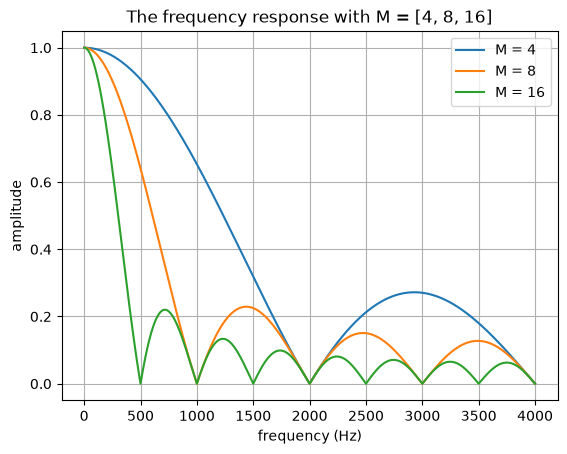

In [6]:
H = np.abs(np.fft.rfft(h_signal, n=8000))
freqs_h = np.fft.rfftfreq(8000, 1/sr)

freqs_h_200 = np.argmin(np.abs(freqs_h - 200))
freqs_h_2500 = np.argmin(np.abs(freqs_h - 2500))
H_200 = H[freqs_h_200]
H_2500 = H[freqs_h_2500]

print(f"The filter coefficients (h) size after FFT : {len(H)}")
print(f"The filter coefficients (h) at 200 Hz : {round(H_200,3)}")
print(f"The filter coefficients (h) at 2500 Hz : {round(H_2500,3)}")

fig, axes = plt.subplots()
axes.set(xlabel="frequency (Hz)", ylabel="amplitude", title="The frequency response with M = [4, 8, 16]")
axes.grid()

for M in [4, 8, 16]:
    h = np.ones(M)/M 
    H = np.abs(np.fft.rfft(h, n=8000))

    n = np.argmax(H < 1e-6)
    print(f"M = {M} and the first frequency the approches 0 is {freqs_h[n]}")

    axes.plot(freqs_h, H, label=f"M = {M}")
    axes.legend(loc="upper right")

**F1 (ทฤษฎี + โค้ด) Convolution theorem — อ่าน ThinkDSP หัวข้อ 8.4 The convolution theorem และ 8.6 Efficient convolution**
  - **ทำ:**
    - ทำต่อใน `notebooks/07_Filters.ipynb`
    - เขียนสรุป convolution theorem ด้วยคำของตัวเอง 2–3 ประโยคลง markdown
    > convolution theorem เป็นเครื่องมือทางคณิตศาสตร์หนึ่งที่สังเกตพฤติกรรมของ input signal ว่าเมื่อไหลผ่านระบบหรือตัวกรอง the filter coefficients แล้วมีการเปลี่ยนแปลงอย่างไร การ Application ที่พบก็เป็นการทำ Blur ใน Image Processing, การสร้าง Filters สำหรับการกรองความถี่ ความสำคัญของมันคือ $f*g = IDFT(DFT(f) \cdot DFT(g))$ มันทำให้การคำนวณ Convolution เร็วขึ้นจากเดิม $N^2$ จะเหลือเพียง $Nlog_{2}N$
    - `x = [1, 2, 3, 4]`, `h = [0.5, 0.5]` → `n = len(x) + len(h) - 1`
    - FFT ทั้งสองตัวด้วย `n=n` → คูณกัน → `np.fft.ifft(...).real` → print ผล
    - เช็ค `np.allclose` กับ `np.convolve(x, h)`
    - ทำซ้ำแต่ใช้ `n=4` (ไม่เติม 0 ให้พอ) → print ผล
    - เพิ่ม `fft_convolve(x, h)` พร้อม docstring ใน `dsp/filters.py` → ทดสอบกับ `[1, 2, 3, 4]` ก่อน
    - ทดสอบกับสัญญาณยาว: `x` จาก C2 กับ `h = np.ones(8) / 8` → เช็ค `np.allclose` กับ `np.convolve` (แบบ default) และ print `len`
  - **เครื่องมือใหม่:**
    - `np.fft.ifft(np.fft.fft([1, 2]))` → `[1, 2]` (แปลงกลับเป็นสัญญาณเวลา แต่ได้เป็นเชิงซ้อน)
    - `.real` → เอาเฉพาะส่วนจริง: `np.array([1+0j, 2+0j]).real` → `[1., 2.]`
  - **ตอบ:**
    1. ผลจาก FFT ด้วย `n=5` ได้อะไร
    > ผลลัพธ์ที่ได้จากการทำมีค่าเท่ากับ np.convolve(x,h) = [0.5 1.5 2.5 3.5 2. ]
    2. ผลด้วย `n=4` ตัวแรกได้เท่าไร
    > ผลลัพธ์จากการทำ Convolution ตัวแรกมีค่าเท่ากับ 2.5
    3. ตัวแรกนั้นเท่ากับ 0.5 บวกกับตัวไหนของผลที่ถูกต้อง
    > บวกกับตัวสุดท้ายของ n=5 นั่นคือ 2 ดังนั้น 0.5 + 2 จึงเท่ากับ 2.5 ซึ่งเราเรียกสิ่งนี้ว่า Wrap-around
  - **เสร็จเมื่อ:** `n=5` ได้ `[0.5, 1.5, 2.5, 3.5, 2.0]` / `n=4` ได้ `[2.5, 1.5, 2.5, 3.5]` / import `fft_convolve` จาก `dsp.filters` ได้ / สัญญาณยาวได้ True และ `len` 8007 และตอบครบ 3 ข้อ

In [7]:
x = [1, 2, 3, 4]
h = [0.5, 0.5]
n = len(x)+len(h)-1

for m in [n, 4]:
    X = np.fft.fft(x, n=m)
    H = np.fft.fft(h, n=m)
    f_g = X * H
    Inv_f_g = np.fft.ifft(f_g).real
    print(f"Results after Inverse FFT when n = {m} : {Inv_f_g}")


print(f"Results from fft_convolve(x,h) : {fft_convolve(x,h)}")
print("Verify whether the value of np.convolve(x,h) = fft_convolve(x,h) by using np.allclose()")
print(f"{np.allclose(fft_convolve(x,h),np.convolve(x,h))}")


Results after Inverse FFT when n = 5 : [0.5 1.5 2.5 3.5 2. ]
Results after Inverse FFT when n = 4 : [2.5 1.5 2.5 3.5]
Results from fft_convolve(x,h) : [0.5 1.5 2.5 3.5 2. ]
Verify whether the value of np.convolve(x,h) = fft_convolve(x,h) by using np.allclose()
True


In [8]:
sr = 8000
t = make_time(0, 1, sr)
x = create_sin(1, 200, t) + create_sin(0.5, 2500, t)
h = np.ones(8)/8 
print("Verify whether the value of np.convolve(x,h) = fft_convolve(x,h) by using np.allclose()")
print(f"{np.allclose(fft_convolve(x,h),np.convolve(x,h))}")
print(f"Size of output after fft_convolve() : {len(fft_convolve(x,h))}")

Verify whether the value of np.convolve(x,h) = fft_convolve(x,h) by using np.allclose()
True
Size of output after fft_convolve() : 8007


**F2 (โค้ด + หู) High-pass filter จาก kernel `[1, -1]`**
  - **ทำ:**
    - ทำนายก่อนรัน: moving average คือ "เฉลี่ย" ค่าข้างกัน ส่วน `[1, -1]` คือ "ลบ" ค่าข้างกัน → sine ความถี่ต่ำ (ค่าข้างกันเกือบเท่ากัน) จะเหลือมากหรือน้อย เขียนลง markdown
    > คิดว่าจะเหลือน้อยลง เพราะว่า จากชื่อแล็ปมันคือ High-pass filter ถ้าเอา concept เดียวกันกับ low-pass filter ก็จะหมายความว่า เป็นการกรองความถี่สูงผ่าน ดังนั้น ความถี่ต่ำก็จะต้องลดลง
    - ใช้ `x` จาก C2 (200 Hz + 2500 Hz, `sr = 8000`)
    - `y = np.convolve(x, [1, -1], mode='same')` → print gain `Y / X` ที่ 200 Hz กับ 2500 Hz (วิธีเดียวกับ C2)
    - `H = np.abs(np.fft.rfft([1, -1], n=8000))` → print `H` ที่ 0 Hz, 200 Hz, 2500 Hz และ 4000 Hz
    - พล็อต `H` ของ `[1, -1]` กับ `np.ones(8) / 8` ในกราฟเดียว (มี legend)
    - ฟัง `x` กับ `y` ด้วย `Audio(..., rate=sr)`
  - **ตอบ:**
    1. gain ที่ 200 Hz ได้เท่าไร
    > gain ที่ 200 Hz มีค่าประมาณ 0.157
    2. gain ที่ 2500 Hz ได้เท่าไร
    > gain ที่ 2500 Hz มีค่าประมาณ 1.663
    3. ฟัง `y` แล้วเสียงไหนเบาลงชัด: เสียงทุ้ม หรือเสียงแหลม
    > หลังจากฟังแล้วเสียงของสัญญาณ x จะมีเสียงแหลมและเสียงทุ้มที่เกิดพร้อม ๆ กัน แต่เมื่อฟังเสียงของสัญญาณ y แล้วจะมีเพียงเสียงแหลมที่เด่นออกมาอย่างชัดเจน เนื่องจาก เกิดการกรองเอาความถี่ต่ำออกมาบางส่วน ด้วยการใช้งาน High-pass filter
  - **เสร็จเมื่อ:** gain ≈0.157 กับ ≈1.663 / `H` ที่ 0, 200, 2500, 4000 Hz ได้ 0, ≈0.157, ≈1.663, 2.0 / มีกราฟ 2 เส้นที่ไขว้กัน และตอบครบ 3 ข้อ

Gain of Y/X at 200 Hz : 0.157
Gain of Y/X at 2500 Hz : 1.663
The frequency response of filter coefficients.
at 0 Hz : 0.0
at 200 Hz : 0.157
at 2500 Hz : 1.663
at 4000 Hz : 2.0


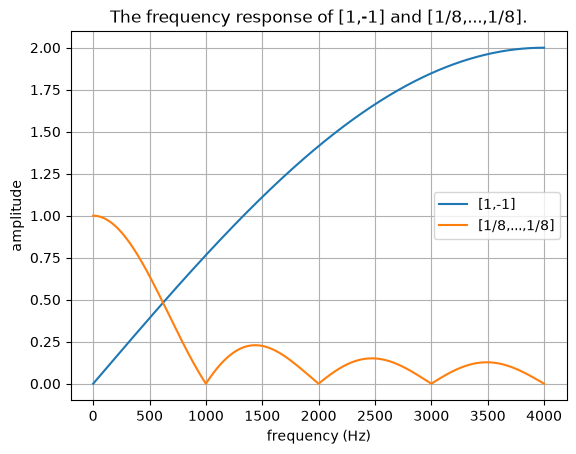

In [9]:
# Create a new signal for lab F2 to prevent confusion.
sr_f2 = 8000
t_f2 = make_time(0, 1, sr_f2)
x_f2 = create_sin(1, 200, t_f2) + create_sin(0.5, 2500, t_f2)
freqs_f2 = np.fft.rfftfreq(8000, 1/sr_f2)
freqs_f2_0 = np.argmin(np.abs(freqs_f2))    # frequency at 0 Hz for the filter coefficients
freqs_f2_200 = np.argmin(np.abs(freqs_f2 - 200))
freqs_f2_2500 = np.argmin(np.abs(freqs_f2 - 2500))
freqs_f2_4000 = np.argmin(np.abs(freqs_f2 - 4000))

# Convolution 
y_f2 = np.convolve(x_f2, [1,-1], mode="same")

# FFT
X_f2 = np.abs(np.fft.rfft(x_f2))
Y_f2 = np.abs(np.fft.rfft(y_f2))
H = np.abs(np.fft.rfft([1,-1], n=8000)) 
H_8 = np.abs(np.fft.rfft(np.ones(8)/8, n=8000)) 

print(f"Gain of Y/X at 200 Hz : {round(Y_f2[freqs_f2_200]/X_f2[freqs_f2_200], 3)}")
print(f"Gain of Y/X at 2500 Hz : {round(Y_f2[freqs_f2_2500]/X_f2[freqs_f2_2500], 3)}")
print(f"The frequency response of filter coefficients.")
print(f"at 0 Hz : {round(H[freqs_f2_0],3)}")
print(f"at 200 Hz : {round(H[freqs_f2_200],3)}")
print(f"at 2500 Hz : {round(H[freqs_f2_2500],3)}")
print(f"at 4000 Hz : {round(H[freqs_f2_4000],3)}")

# Plot 
fig, axes = plt.subplots()
axes.set(xlabel="frequency (Hz)", ylabel="amplitude", title="The frequency response of [1,-1] and [1/8,...,1/8].")
axes.grid()

axes.plot(freqs_f2, H, label="[1,-1]")
axes.plot(freqs_f2, H_8, label="[1/8,...,1/8]")
axes.legend(loc="center right")

In [10]:
Audio(x_f2,rate=sr_f2)

In [11]:
Audio(y_f2,rate=sr_f2)

**F3 (โค้ด + หู) Echo = convolution กับ impulse response**
  - **ทำ:**
    - `sr = 8000` สร้างโน้ต 440 Hz แอมพลิจูด 0.5 ยาว 0.2 วินาที → `len` ได้ 1600
    - kernel echo: `h = np.zeros(2401)` → `h[0] = 1`, `h[2400] = 0.5` (ดีเลย์ 0.3 วินาที เบาลงครึ่งหนึ่ง)
    - `y = fft_convolve(note, h)` → print `len(y)`
    - หา index แรกหลัง 1600 ที่ `np.abs(y) > 0.01` → แปลงเป็นวินาที
    - print ค่าสูงสุดของ `np.abs(y)` ในช่วงก่อน 1600 และหลัง 1600
    - วัดเวลา `convolve(note, h)` (ของเราจาก C1) เทียบกับ `fft_convolve(note, h)` → เช็ค `np.allclose` ของผลทั้งสอง
    - ฟัง `note` กับ `y` ด้วย `Audio(..., rate=sr)`
  - **เครื่องมือใหม่:**
    - วัดเวลา: `import time` → `t0 = time.perf_counter()` → รันโค้ด → `time.perf_counter() - t0` ได้เวลาเป็นวินาที
  - **ใบ้:** `convolve` ของเราต้องวน loop ประมาณ 4000 × 2401 รอบ ใช้เวลาหลายวินาทีเป็นเรื่องปกติ
  - **ตอบ:**
    1. `len(y)` ได้เท่าไร
    > len(y) ได้เท่ากับ 4000
    2. echo เริ่มที่กี่วินาที
    > Echo เริ่มต้นที่ 0.3 วินาที
    3. แอมพลิจูดสูงสุดของ echo ได้เท่าไร
    > แอมพลิจูดสูงสุดของ echo มีค่าเท่ากับ 0.25
  - **เสร็จเมื่อ:** `len(y)` ได้ 4000 / echo เริ่ม ≈0.30 s (index 2401 เพราะ sample แรกของ sine เป็น 0) / สูงสุดก่อน 1600 ได้ 0.5 หลัง 1600 ได้ 0.25 / `np.allclose` ได้ True และ `fft_convolve` เร็วกว่ามากกว่า 100 เท่า / ฟังแล้วได้ยินโน้ต 2 ครั้ง และตอบครบ 3 ข้อ

In [12]:
sr_f3 = 8000
t_f3 = make_time(0, 0.2, sr_f3)
notes = create_sin(0.5, 440, t_f3)

print(f"Check size of signal : {len(notes)}")

# kernel echo
h = np.zeros(2401)
h[0] = 1
h[2400] = 0.5

y = fft_convolve(notes, h)
print(f"Check size of convolution signal : {len(y)}")

index = np.argmax(np.abs(y[1600:])>0.01)+1600
t_index = (index / sr_f3) 
print(f"Echo start at : {round(t_index,3)} seconds.")

max_before_1600 = np.max(np.abs(y[:1600]))
max_after_1600 = np.max(np.abs(y[1600:]))
print(f"Maximum values of np.abs(y) before 1600 Hz : {round(max_before_1600,4)}")
print(f"Maximum values of np.abs(y) after 1600 Hz : {round(max_after_1600,4)}")

# Compare time duration to compute convolution between convolve() and fft_convolve
# Timing compute of convolve()
start_time_convolve = time.perf_counter()
result_convolve = convolve(notes, h)
end_time_convolve = time.perf_counter()
period_convolve = end_time_convolve - start_time_convolve
print(f"Time duration of convolve() : {period_convolve} seconds.")

# Timing compute of fft_convolve()
start_time_fft = time.perf_counter()
result_fft = fft_convolve(notes, h)
end_time_fft = time.perf_counter()
period_fft = end_time_fft - start_time_fft
print(f"Time duration of fft_convolve() : {period_fft} seconds.")

print(f"Diff compute time between fft_convolve and convolve : {period_convolve/period_fft}")

print("Verify that convolve() is equal fft_convolve with np.allclose()")
print(np.allclose(result_convolve, result_fft))

Check size of signal : 1600
Check size of convolution signal : 4000
Echo start at : 0.3 seconds.
Maximum values of np.abs(y) before 1600 Hz : 0.5
Maximum values of np.abs(y) after 1600 Hz : 0.25
Time duration of convolve() : 2.8091150999534875 seconds.
Time duration of fft_convolve() : 0.00035769998794421554 seconds.
Diff compute time between fft_convolve and convolve : 7853.2714415175715
Verify that convolve() is equal fft_convolve with np.allclose()
True


In [13]:
Audio(notes, rate=sr)

In [14]:
Audio(y, rate=sr)